# Hotel booking cancellation prediction

Hotels lose revenue when a reserved room is cancelled and cannot be resold in time. This notebook asks a practical question: **using only information that can be known when the booking is made, or that does not reveal the final reservation status, how likely is this booking to be cancelled?**

The target is `is_canceled` (1 = cancelled, 0 = kept). The model is a probability model, not a hard rule. Front-office and revenue teams can rank bookings and decide where a reminder, a deposit policy, or an overbooking buffer is worth the guest-experience cost.

This notebook is the exploratory analysis. The same training procedure is exported as `train.py`, which calls `hotel_ml.run_experiment`.


## Data source

The rows come from the Hotel Booking Demand dataset published by Nuno Antonio, Ana de Almeida, and Luis Nunes in *Data in Brief* (2019), DOI [10.1016/j.dib.2018.11.126](https://doi.org/10.1016/j.dib.2018.11.126). The file used here is the public TidyTuesday redistribution of that dataset (week of 11 February 2020), which cites the article:

<https://github.com/rfordatascience/tidytuesday/tree/master/data/2020/2020-02-11>

The journal article is open access. TidyTuesday documents the column definitions copied into `data/tidytuesday_readme.md`. The download is checked by `download_data.py` against SHA-256 `7c2ae42a7353905ea136e5c2287f17c92c5435826598bfbb8491c6f0c7b1fc06`.

Two hotels in Portugal are included: a resort hotel and a city hotel, with arrivals from 2015 through 2017. This is not a random sample of the global hotel industry.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from hotel_ml import FEATURES, LEAKAGE_OR_UNAVAILABLE, TARGET, load_raw, prepare

sns.set_theme(style="whitegrid")
FIG = Path("reports/figures")
FIG.mkdir(parents=True, exist_ok=True)

raw = load_raw(Path("data/hotel_bookings.csv"))
print("Raw shape:", raw.shape)
print("Columns:", list(raw.columns))


Raw shape: (119390, 32)
Columns: ['hotel', 'is_canceled', 'lead_time', 'arrival_date_year', 'arrival_date_month', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'meal', 'country', 'market_segment', 'distribution_channel', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'reserved_room_type', 'assigned_room_type', 'booking_changes', 'deposit_type', 'agent', 'company', 'days_in_waiting_list', 'customer_type', 'adr', 'required_car_parking_spaces', 'total_of_special_requests', 'reservation_status', 'reservation_status_date']


## What a model is allowed to see

`reservation_status` is essentially the target written as text (`Canceled`, `Check-Out`, `No-Show`). `reservation_status_date` is the date that final status was written. Both are excluded.

`assigned_room_type` can differ from the reserved type because of hotel operations at arrival, so it is not treated as a booking-time feature. `booking_changes` accumulates until check-in or cancellation, so the value depends on when you look. `agent` and `company` are anonymous IDs with many missing values; they would not transfer cleanly to a new property.

`required_car_parking_spaces` is kept because the published dictionary defines it as a customer request. In this file, every booking with a parking request is kept. That separation is extreme enough that it may be a property-management-system habit rather than a stable business rule. The model report treats it as a feature to audit, not as a reason to auto-cancel a booking.


In [2]:
prepared, notes = prepare(raw)
print(pd.Series(notes))
print("Cancellation rate after cleaning:", round(prepared[TARGET].mean(), 4))
print("Leakage or unavailable columns excluded:", LEAKAGE_OR_UNAVAILABLE)
print("Feature count:", len(FEATURES))


rows_raw                         119390.000000
exact_duplicate_rows              31994.000000
rows_after_dedup                  87396.000000
invalid_arrival_dates_removed         0.000000
zero_guest_rows_removed             166.000000
negative_adr_set_to_missing           1.000000
rows_model                        87230.000000
cancellation_rate                     0.275238
dtype: float64
Cancellation rate after cleaning: 0.2752
Leakage or unavailable columns excluded: ['reservation_status', 'reservation_status_date', 'assigned_room_type', 'booking_changes', 'agent', 'company']
Feature count: 25


## Missing values, duplicates, and the target

About 32,000 rows are exact duplicates. Keeping them would let identical bookings fall into more than one split and would inflate the apparent size of some deposit segments. They are removed before the time split.

`company` is missing for most rows and `agent` for a smaller share. `country` and `children` are rarely missing. One negative average daily rate is treated as missing rather than as a real price.

After cleaning, about 27.5% of bookings are cancelled. That is lower than the often-quoted 37% on the raw file, because the duplicate rows are not counted twice.


Missing percent:
company     94.307
agent       13.686
country      0.409
children     0.003
Target counts:
is_canceled
0    0.6296
1    0.3704
Name: proportion, dtype: float64


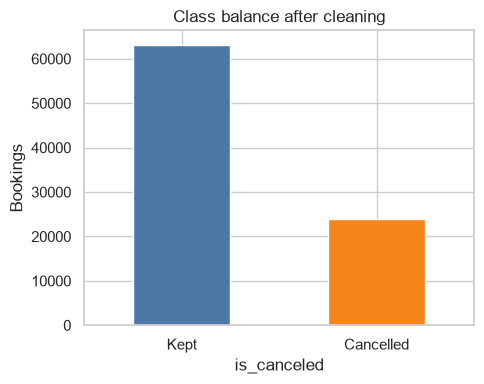

In [3]:
display_frame = raw.replace({"NULL": np.nan, "": np.nan})
missing = display_frame.isna().mean().mul(100).sort_values(ascending=False)
missing = missing[missing > 0]
print("Missing percent:")
print(missing.round(3).to_string())
print("Target counts:")
print(raw[TARGET].value_counts(normalize=True).round(4))

fig, ax = plt.subplots(figsize=(5, 4))
prepared[TARGET].value_counts().sort_index().plot(kind="bar", ax=ax, color=["#4C78A8", "#F58518"])
ax.set_xticklabels(["Kept", "Cancelled"], rotation=0)
ax.set_ylabel("Bookings")
ax.set_title("Class balance after cleaning")
fig.tight_layout()
fig.savefig(FIG / "class_balance.png", dpi=140)
plt.show()


## Lead time

Longer lead times cancel more often. Bookings made within a week of arrival cancel at roughly 8%. Bookings made more than six months ahead cancel at roughly 40%. A hotel can use lead time as a planning signal, but it is not destiny: many long-lead bookings still arrive.


lead_bin
0-7 days       0.084
8-30 days      0.254
31-90 days     0.320
91-180 days    0.350
181+ days      0.397
Name: is_canceled, dtype: float64


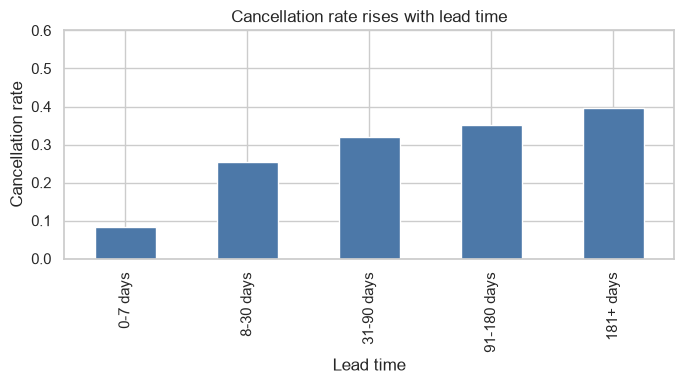

In [4]:
prepared = prepared.copy()
prepared["lead_bin"] = pd.cut(
    prepared["lead_time"],
    bins=[-0.1, 7, 30, 90, 180, prepared["lead_time"].max()],
    labels=["0-7 days", "8-30 days", "31-90 days", "91-180 days", "181+ days"],
)
lead_rate = prepared.groupby("lead_bin", observed=True)[TARGET].mean()
print(lead_rate.round(3))

fig, ax = plt.subplots(figsize=(7, 4))
lead_rate.plot(kind="bar", ax=ax, color="#4C78A8")
ax.set_ylabel("Cancellation rate")
ax.set_xlabel("Lead time")
ax.set_title("Cancellation rate rises with lead time")
ax.set_ylim(0, 0.6)
fig.tight_layout()
fig.savefig(FIG / "cancellation_by_lead_time.png", dpi=140)
plt.show()


## Deposit, hotel, and customer type

Non-refundable deposits are rare after de-duplication (about 1,000 bookings) but almost all of them are cancelled (about 95%). No-deposit bookings, which are nearly the whole file, cancel at about 27%. A model that only memorizes "non-refundable means cancelled" will look strong on a tiny slice and will not help the typical booking.

City-hotel bookings cancel more often than resort bookings (about 30% versus 23%). Transient guests cancel more often than contract, transient-party, or group bookings. Those differences are useful for operations, and they are visible before arrival.



 deposit_type
              cancellation_rate  bookings
deposit_type                             
Non Refund                0.947      1038
No Deposit                0.267     86085
Refundable                0.243       107

 hotel
              cancellation_rate  bookings
hotel                                    
City Hotel                0.301     53274
Resort Hotel              0.235     33956

 customer_type
                 cancellation_rate  bookings
customer_type                               
Transient                    0.301     71862
Contract                     0.163      3135
Transient-Party              0.152     11692
Group                        0.098       541


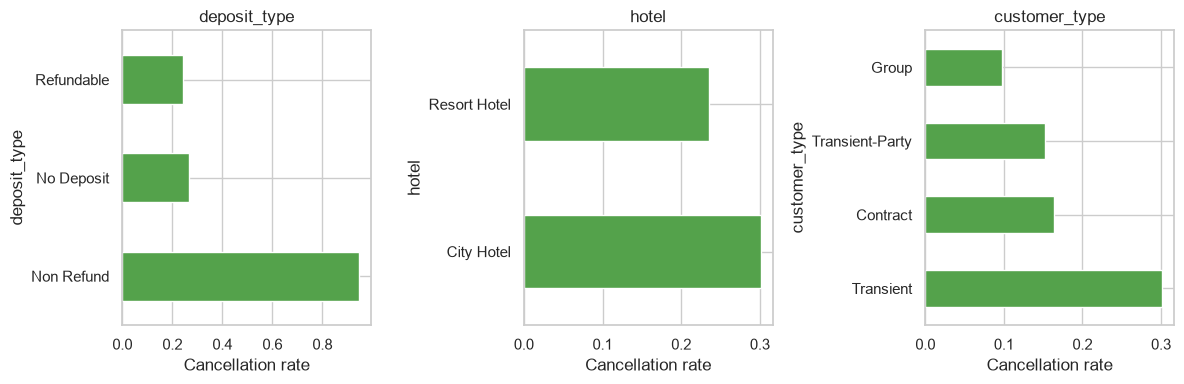

In [5]:
def rate_table(column):
    table = prepared.groupby(column)[TARGET].agg(cancellation_rate="mean", bookings="size")
    return table.sort_values("cancellation_rate", ascending=False)

for column in ["deposit_type", "hotel", "customer_type"]:
    print("\n", column)
    print(rate_table(column).round(3))

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, column in zip(axes, ["deposit_type", "hotel", "customer_type"]):
    table = rate_table(column)
    table["cancellation_rate"].plot(kind="barh", ax=ax, color="#54A24B")
    ax.set_xlabel("Cancellation rate")
    ax.set_title(column)
fig.tight_layout()
fig.savefig(FIG / "cancellation_by_segment.png", dpi=140)
plt.show()


## Seasonality

Summer arrivals cancel more often than late-autumn and winter arrivals. August is the highest month in this file (about 32%) and November is among the lowest (about 21%). Seasonality matters for staffing and overbooking, but the gap is smaller than the gap by lead time or by deposit type.


arrival_date_month
January      0.221
February     0.232
March        0.244
April        0.305
May          0.293
June         0.303
July         0.318
August       0.322
September    0.246
October      0.237
November     0.212
December     0.269
Name: is_canceled, dtype: float64


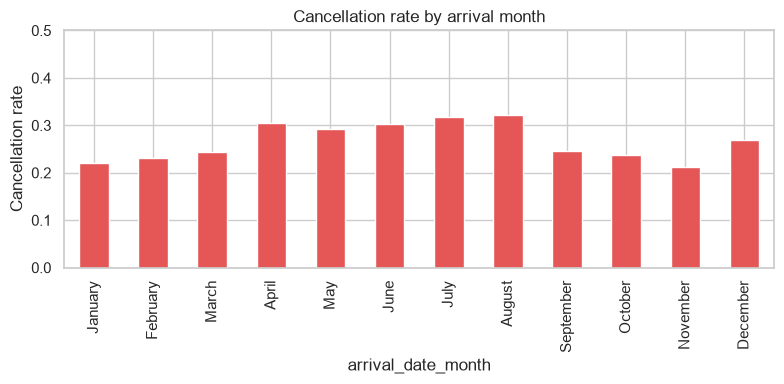

In [6]:
month_order = ["January","February","March","April","May","June","July","August","September","October","November","December"]
month_rate = prepared.groupby("arrival_date_month")[TARGET].mean().reindex(month_order)
print(month_rate.round(3))
fig, ax = plt.subplots(figsize=(8, 4))
month_rate.plot(kind="bar", ax=ax, color="#E45756")
ax.set_ylabel("Cancellation rate")
ax.set_title("Cancellation rate by arrival month")
ax.set_ylim(0, 0.5)
fig.tight_layout()
fig.savefig(FIG / "cancellation_by_month.png", dpi=140)
plt.show()


## Other booking-time signals

Guests who make more special requests cancel less often. Bookings that request at least one parking space do not appear as cancellations anywhere in the cleaned file. That second pattern is strong enough to dominate a tree model, so it is reported separately in the feature-importance table and should be checked against the hotel's own reservation system before anyone uses it as policy.

Average daily rate has a long right tail and one negative value, which was set to missing. Price is a weak permutation signal compared with market segment, country, and lead time.


total_of_special_requests
0    0.333
1    0.224
2    0.213
3    0.171
4    0.106
5    0.056
Name: is_canceled, dtype: float64
Cancellation rate when parking was requested: 0.0
Bookings with a parking request: 7306


C:\Users\ArshAITransformation\AppData\Local\Temp\ipykernel_22732\20758502.py:7: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(["Kept", "Cancelled"])


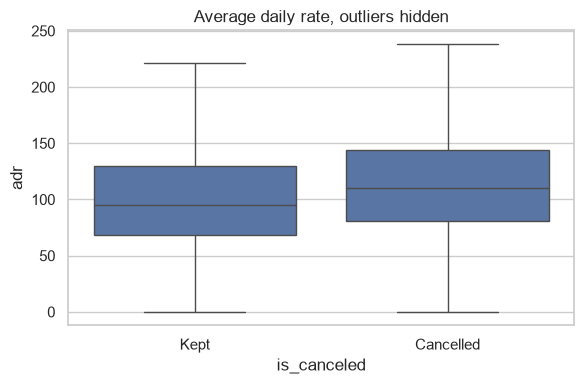

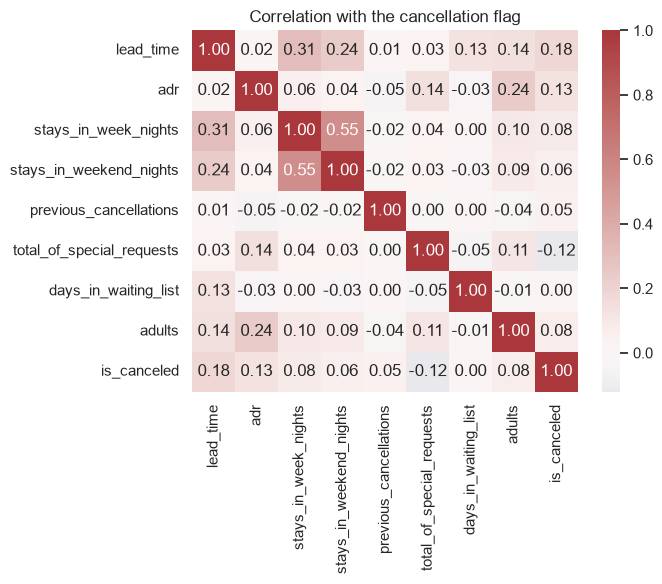

In [7]:
print(prepared.groupby("total_of_special_requests")[TARGET].mean().round(3))
print("Cancellation rate when parking was requested:", prepared.loc[prepared["required_car_parking_spaces"] > 0, TARGET].mean())
print("Bookings with a parking request:", int((prepared["required_car_parking_spaces"] > 0).sum()))

fig, ax = plt.subplots(figsize=(6, 4))
sns.boxplot(data=prepared, x=TARGET, y="adr", ax=ax, showfliers=False)
ax.set_xticklabels(["Kept", "Cancelled"])
ax.set_title("Average daily rate, outliers hidden")
fig.tight_layout()
fig.savefig(FIG / "adr_by_cancellation.png", dpi=140)
plt.show()

numeric = ["lead_time", "adr", "stays_in_week_nights", "stays_in_weekend_nights", "previous_cancellations", "total_of_special_requests", "days_in_waiting_list", "adults"]
corr = prepared[numeric + [TARGET]].corr(numeric_only=True)
fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0, ax=ax)
ax.set_title("Correlation with the cancellation flag")
fig.tight_layout()
fig.savefig(FIG / "correlation_heatmap.png", dpi=140)
plt.show()


## What the exploration changes about the model

The useful story is not "a few magic columns". Lead time, guest type, hotel type, season, special requests, and a small non-refundable segment all move the cancellation rate in ways a revenue manager already suspects. Exact duplicate rows and status fields would make the problem look easier than it is. The training script therefore sorts bookings by an estimated booking date, `arrival_date - lead_time`, and keeps the latest 20% of bookings as an untouched test set.

The operating question for the hotel is ranking plus a threshold. ROC AUC asks whether cancelled bookings receive higher scores than kept bookings. Precision asks how often a flagged booking really cancels. Recall asks how many cancellations the hotel actually catches. False alarms create awkward guest contact or unnecessary overbooking. Missed cancellations leave empty rooms. The threshold is chosen on the validation period to maximize F1, then frozen before the test period is scored.


## Model comparison

`train.py` fits four families inside scikit-learn pipelines. Imputers and encoders are fit only on each training fold. The comparison metric is mean ROC AUC from a three-split `TimeSeriesSplit` on the training period. Hyperparameters are chosen with `GridSearchCV` for every family:

- logistic regression: `C` in {0.1, 1, 10}
- decision tree: `max_depth` in {4, 8, 12}
- random forest: `max_depth` in {8, 16} and `min_samples_leaf` in {5, 20}
- histogram gradient boosting: `learning_rate` in {0.05, 0.1} and `max_depth` in {3, 6}

The selected model is the one with the highest cross-validated ROC AUC, not the highest training score. The cell below reads the metrics written by that run. Re-run `python train.py` to regenerate them.


In [8]:
import json
metrics = json.loads(Path("reports/metrics.json").read_text(encoding="utf-8"))
comparison = pd.DataFrame(metrics["model_comparison"])
print(comparison.to_string(index=False))
print("Selected:", metrics["selected_model"], metrics["selected_params"])
print("Threshold:", metrics["threshold"])
print("Train:", metrics["train_at_selected_threshold"])
print("Validation:", metrics["validation"])
print("Test:", metrics["test"])
importance = pd.read_csv("reports/permutation_importance.csv").head(10)
print(importance.to_string(index=False))


                 model                                            best_params  cv_roc_auc_mean  cv_roc_auc_std
hist_gradient_boosting   {'model__learning_rate': 0.1, 'model__max_depth': 3}         0.796131        0.061529
         random_forest {'model__max_depth': 16, 'model__min_samples_leaf': 5}         0.794185        0.051370
   logistic_regression                                      {'model__C': 0.1}         0.779452        0.020290
         decision_tree                                {'model__max_depth': 8}         0.750966        0.055865
Selected: hist_gradient_boosting {'model__learning_rate': 0.1, 'model__max_depth': 3}
Threshold: 0.4
Train: {'roc_auc': 0.9047915688948044, 'precision': 0.6859602649006622, 'recall': 0.738169897377423, 'f1': 0.71110805986544, 'threshold': 0.4, 'confusion_matrix': {'tn': 33564, 'fp': 4742, 'fn': 3674, 'tp': 10358}}
Validation: {'roc_auc': 0.8352603660579954, 'precision': 0.5381401617250674, 'recall': 0.777150642273258, 'f1': 0.635929288103201

## How to read the measured result

Histogram gradient boosting won the training-period comparison, with a mean ROC AUC of about 0.796. A random forest was very close. Logistic regression was a little lower and more stable across folds. The shallow tree was the weakest.

On the later validation period the selected model reaches about 0.835 ROC AUC. On the untouched test period, bookings from 28 January 2017 through 31 August 2017, ROC AUC is about 0.826. Training ROC AUC is higher, about 0.905, so some optimism remains, but the drop from validation to test is small.

At the validation-chosen threshold of 0.40, the test set catches about 86% of cancellations and is right about 47% of the time it raises a flag. That is a recall-leaning operating point. A hotel that dislikes guest contact would move the threshold up and accept more missed cancellations. The confusion counts are in `reports/metrics.json`.

Permutation importance on a validation sample puts market segment, parking requests, country, and lead time at the top. Market segment and country are real booking attributes, but country codes can encode local distribution patterns that will not copy to another city. Parking is the feature to audit before deployment.


## Limits

The two Portuguese hotels and the 2015–2017 window are not a forecast for every property. De-duplication changes the class balance relative to the raw extract. The estimated booking date is arrival date minus lead time; the file has no separate creation timestamp except through that definition. No live PMS feed was used. The API serves this saved pipeline only. It does not retrain when a request arrives.
